In [1]:
"""
Notebook 03 v3 — Exploratory Data Analysis & Feature Diagnostics

Purpose:
    Inspect the raw time-series data before modelling. Verify data
    quality, look for obvious problems, quantify multicollinearity,
    and confirm that the fire signal is present in the observations.

Inputs:
    full_pixels_10m.csv  (from Notebook 02 v3)

Outputs:
    selected_features.json  — the feature list downstream notebooks read
    EDA figures for the thesis

Structure:
    1. Descriptive statistics
    2. Data-quality diagnostics
    3. Correlation and multicollinearity (VIF)
    4. Land-cover distribution and fire prevalence by LC class
    5. Phenomenological visualisation — the fire signal in NBR
    6. Feature selection decision
"""

'\nNotebook 03 v3 — Exploratory Data Analysis & Feature Diagnostics\n\nPurpose:\n    Inspect the raw time-series data before modelling. Verify data\n    quality, look for obvious problems, quantify multicollinearity,\n    and confirm that the fire signal is present in the observations.\n\nInputs:\n    full_pixels_10m.csv  (from Notebook 02 v3)\n\nOutputs:\n    selected_features.json  — the feature list downstream notebooks read\n    EDA figures for the thesis\n\nStructure:\n    1. Descriptive statistics\n    2. Data-quality diagnostics\n    3. Correlation and multicollinearity (VIF)\n    4. Land-cover distribution and fire prevalence by LC class\n    5. Phenomenological visualisation — the fire signal in NBR\n    6. Feature selection decision\n'

# Notebook 03 v3 — EDA

In [2]:
# --- Environment auto-detection ---
import sys, os
IS_COLAB = "google.colab" in sys.modules

if IS_COLAB:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    THESIS_ROOT = "/content/drive/MyDrive/thesisv4"
else:
    THESIS_ROOT = os.path.expanduser("~/thesisv4")

sys.path.insert(0, THESIS_ROOT)
print(f"=== Environment: {'COLAB' if IS_COLAB else 'LOCAL'} ===")
print(f"Workspace: {THESIS_ROOT}")

=== Environment: LOCAL ===
Workspace: /home/od/thesisv4


In [3]:
import sys, importlib
# sys.path already set by auto-detect cell above
import config
importlib.reload(config)

config.ensure_dirs()
config.set_seed()
config.print_summary()

CONFIG SUMMARY  (run_v4)
Environment:        Local
Workspace root:     /home/od/thesisv4
GEE project:        YOUR-GEE-PROJECT
Scale:              10 m
CRS:                EPSG:32636
Analysis period:    2017-01 to 2025-12
Analysis months:    108
Baseline years:     [2016, 2017]
Total features:     52
Sampling targets:
  n_no_fires              304,461
  n_low_recurrence        300,032
  n_medium_recurrence       4,050
  n_high_recurrence           379
  quality_threshold           0.2
  TOTAL                   608,922
Model:              d_model=128, n_head=4, d_k=32
Training:           batch_size=256, epochs=50


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

## 1. Load the raw time-series data

In [5]:
# Explicit dtypes: at default (float64) this table is ~30 GB in RAM and the
# sort_values copy doubles that, which does not fit in 64 GB. float32 holds
# ~7 significant digits - well beyond the precision of the source reflectance.
_float_cols = [c for c in (config.ALL_FEATURES + config.LC_FEATURES)
               if c not in ("pixel_id", "year", "month", "burned")]
dtypes = {c: "float32" for c in _float_cols}
dtypes.update({"pixel_id": "int32", "pixel_type": "category",
               "year": "int16", "month": "int8", "burned": "int8"})

_header = pd.read_csv(config.FILES["raw_timeseries"], nrows=0).columns
dtypes = {c: t for c, t in dtypes.items() if c in _header}

df = pd.read_csv(config.FILES["raw_timeseries"], dtype=dtypes)
df = df.sort_values(["pixel_id", "year", "month"], ignore_index=True)

print(f"Memory:  {df.memory_usage(deep=True).sum() / 1e9:.1f} GB")
print(f"Rows:    {len(df):,}")
print(f"Pixels:  {df['pixel_id'].nunique():,}")
print(f"Months per pixel (describe):")
print(df.groupby("pixel_id").size().describe())
print()
print("Pixel-type distribution:")
print(df.groupby("pixel_id")["pixel_type"].first().value_counts())

Memory:  12.6 GB
Rows:    63,882,166
Pixels:  608,922
Months per pixel (describe):
count    608922.000000
mean        104.910261
std           1.792745
min          96.000000
25%         104.000000
50%         105.000000
75%         106.000000
max         108.000000
dtype: float64

Pixel-type distribution:
pixel_type
no_fires             304461
low_recurrence       300032
medium_recurrence      4050
high_recurrence         379
Name: count, dtype: int64


## 2. Data-quality diagnostics

### 2.1 NaN heatmap per feature × month

Spectral features can go missing for a whole month when cloud cover
is heavy; a vertical band in the heatmap identifies such months. A
horizontal band would identify a feature that is chronically
problematic across the whole period. Land-cover features are 0/1 by
construction and should never be NaN.

Not in raw CSV (derived downstream), excluded from EDA: ['delta_NBR', 'delta_NDVI', 'delta_NDMI', 'delta_BAIS2', 'month_cos', 'month_sin']


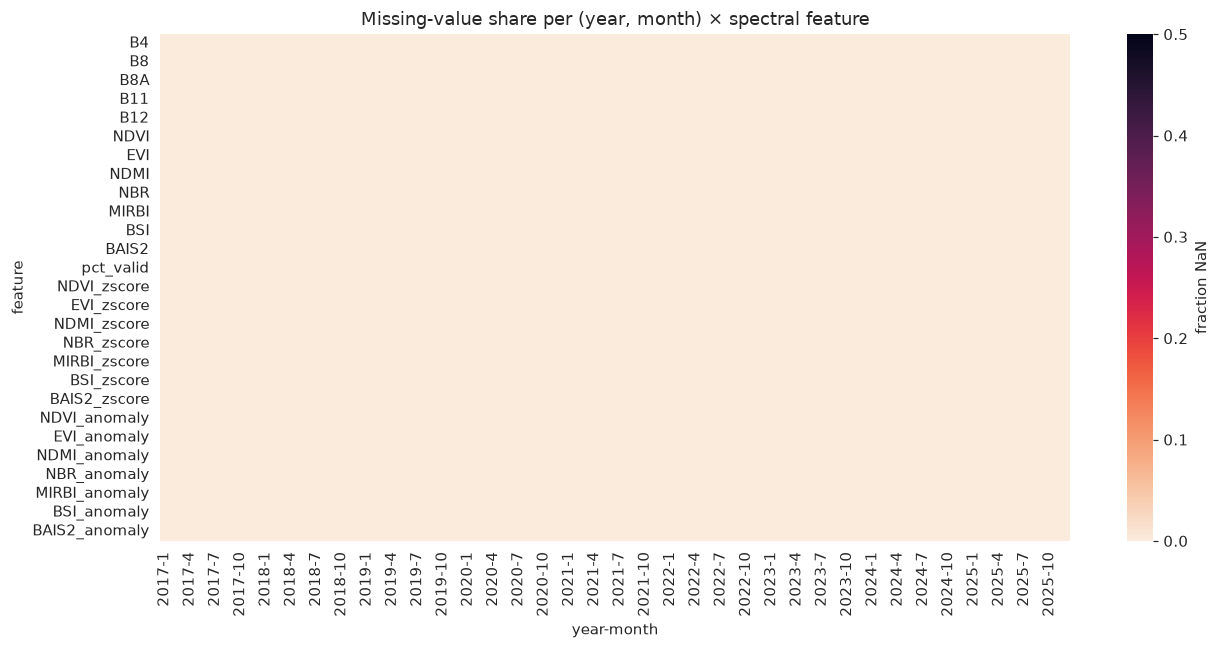

In [6]:
# delta_* and month_cos/sin are engineered downstream (04/07b) and are not
# columns of the raw time-series CSV, so restrict to features actually present.
spectral_features = [f for f in config.ALL_FEATURES
                     if f not in config.LC_FEATURES and f in df.columns]

missing = [f for f in config.ALL_FEATURES
           if f not in config.LC_FEATURES and f not in df.columns]
if missing:
    print(f"Not in raw CSV (derived downstream), excluded from EDA: {missing}")

nan_share = (df.groupby(["year", "month"])[spectral_features]
               .apply(lambda g: g.isna().mean()))

fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(nan_share.T, ax=ax, cmap="rocket_r", vmin=0, vmax=0.5,
            cbar_kws={"label": "fraction NaN"})
ax.set_title("Missing-value share per (year, month) × spectral feature")
ax.set_xlabel("year-month")
ax.set_ylabel("feature")
plt.tight_layout()
plt.show()

### 2.2 Quality band distribution

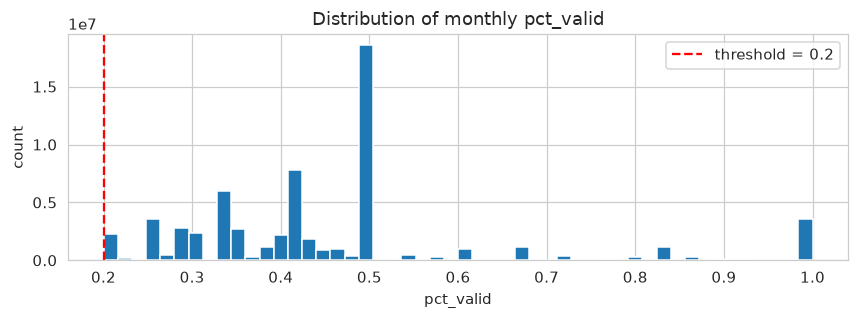

Rows below quality threshold: 0.00%


In [7]:
fig, ax = plt.subplots(figsize=(8, 3))
df["pct_valid"].hist(bins=50, ax=ax, edgecolor="white")
ax.axvline(config.SAMPLING["quality_threshold"], color="red", linestyle="--",
           label=f"threshold = {config.SAMPLING['quality_threshold']}")
ax.set_xlabel("pct_valid")
ax.set_ylabel("count")
ax.set_title("Distribution of monthly pct_valid")
ax.legend()
plt.tight_layout()
plt.show()

below = (df["pct_valid"] < config.SAMPLING["quality_threshold"]).mean()
print(f"Rows below quality threshold: {100 * below:.2f}%")

### 2.3 Burned-month statistics

Burned rows: 335,907 (0.526% of all rows)


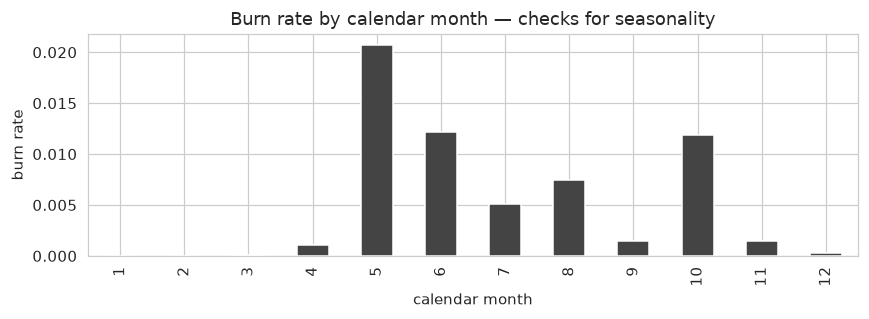

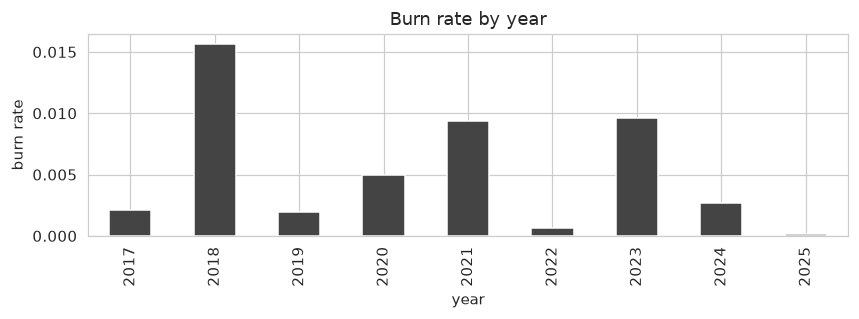

In [8]:
print(f"Burned rows: {df['burned'].sum():,} "
      f"({100 * df['burned'].mean():.3f}% of all rows)")

by_month = df.groupby("month")["burned"].mean()
fig, ax = plt.subplots(figsize=(8, 3))
by_month.plot(kind="bar", ax=ax, color="#444")
ax.set_xlabel("calendar month")
ax.set_ylabel("burn rate")
ax.set_title("Burn rate by calendar month — checks for seasonality")
plt.tight_layout()
plt.show()

by_year = df.groupby("year")["burned"].mean()
fig, ax = plt.subplots(figsize=(8, 3))
by_year.plot(kind="bar", ax=ax, color="#444")
ax.set_xlabel("year")
ax.set_ylabel("burn rate")
ax.set_title("Burn rate by year")
plt.tight_layout()
plt.show()

## 3. Correlation and multicollinearity

### 3.1 Correlation matrix (time-averaged per pixel)

Reduce each pixel's time series to its mean and correlate features.
Only spectral features enter this analysis: land-cover one-hot bands
are perfectly correlated with themselves and would confuse the plot.

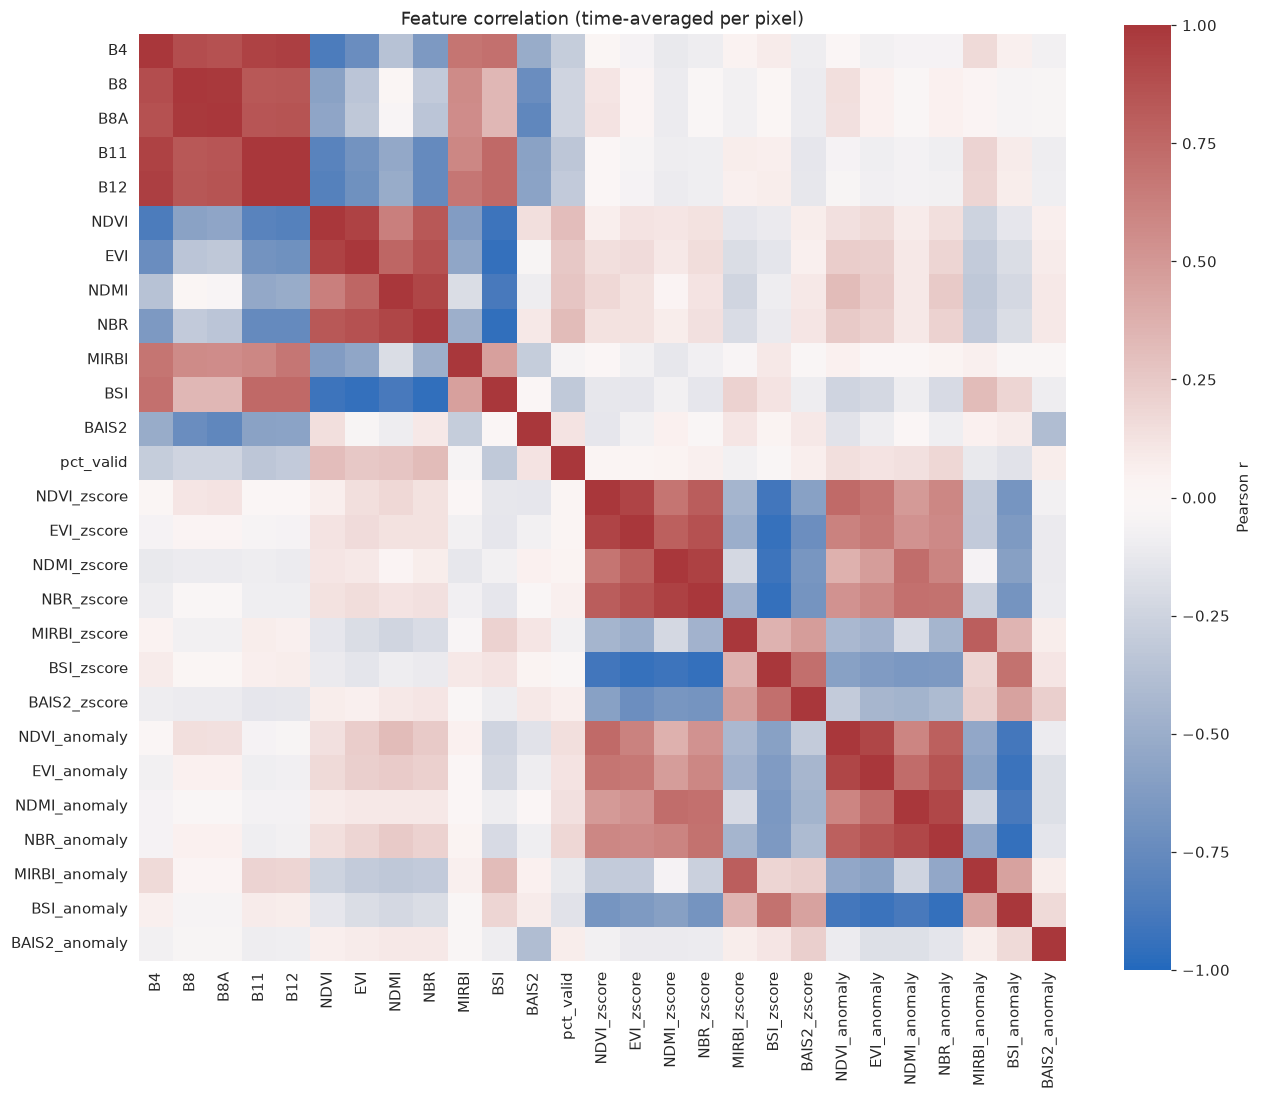

In [9]:
# float64 for the correlation/VIF numerics (df itself is float32 for memory)
pixel_means = df.groupby("pixel_id")[spectral_features].mean().astype("float64")
corr = pixel_means.corr()

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, ax=ax, cmap="vlag", center=0, vmin=-1, vmax=1,
            square=True, cbar_kws={"label": "Pearson r"})
ax.set_title("Feature correlation (time-averaged per pixel)")
plt.tight_layout()
plt.show()

### 3.2 Variance Inflation Factor (VIF)

VIF quantifies how much each feature is explained by the others.
Values above 10 typically indicate problematic multicollinearity.
The v3 pipeline excludes NBR_dnbr from the outset because it is
analytically identical (up to sign) to NBR_anomaly given the
seasonal-baseline formulation. Any remaining high-VIF pairs are
kept if they carry distinct ecological meaning; the L-TAE's
attention mechanism handles the redundancy at training time.

In [10]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif = pixel_means[spectral_features].dropna()
X_vif = (X_vif - X_vif.mean()) / X_vif.std()

vif_df = pd.DataFrame({
    "feature": spectral_features,
    "VIF": [variance_inflation_factor(X_vif.values, i)
            for i in range(len(spectral_features))],
}).sort_values("VIF", ascending=False)

print(vif_df.to_string(index=False))

      feature          VIF
          B12 3.032727e+13
          B11 2.515977e+13
        MIRBI 5.970964e+11
           B4 1.240723e+03
           B8 1.136798e+03
          BSI 7.969552e+02
          EVI 5.320931e+02
         NDMI 5.055208e+02
          B8A 4.723074e+02
         NDVI 3.850413e+02
   NBR_zscore 3.335160e+02
          NBR 2.956461e+02
  NDMI_zscore 2.549362e+02
  NBR_anomaly 2.473688e+02
 NDMI_anomaly 2.003897e+02
   BSI_zscore 1.367374e+02
  BSI_anomaly 1.341476e+02
 NDVI_anomaly 1.104401e+02
  NDVI_zscore 7.971644e+01
        BAIS2 7.389779e+01
   EVI_zscore 5.051153e+01
  EVI_anomaly 4.880783e+01
 MIRBI_zscore 2.580883e+01
MIRBI_anomaly 2.472755e+01
BAIS2_anomaly 1.788096e+01
 BAIS2_zscore 5.939940e+00
    pct_valid 1.314555e+00


## 4. Land-cover distribution and fire prevalence by LC class

### 4.1 Sampled-pixel distribution across LC classes

Uses the current-year LC (one-hot). Each pixel is counted once, using
the mode of its per-month LC label to handle the rare case where a
pixel's LC changed during the analysis period.

In [11]:
lc_curr_cols = config.LC_FEATURES_CURR
lc_codes     = config.LC_CODES
code_to_name = config.LC_CATEGORIES

# Dominant LC per pixel = argmax over the per-pixel sums of the one-hot
# columns. Vectorised form of the previous groupby().apply() loop, which ran
# a Python function per pixel over ~609k pixels; identical result, including
# first-max tie-breaking.
lc_sums  = df.groupby("pixel_id")[lc_curr_cols].sum()
pixel_lc = pd.Series(np.asarray(lc_codes)[np.argmax(lc_sums.values, axis=1)],
                     index=lc_sums.index, name="lc_code")

lc_counts = pixel_lc.value_counts().sort_index()
print("Dominant LC class per pixel:")
for code, n in lc_counts.items():
    print(f"  {code:3d}  {code_to_name.get(code, 'unknown'):22s}  {n:>6,}")

Dominant LC class per pixel:
   10  forest                  49,233
   11  orchards                25,727
   20  shrubland               83,576
   30  grassland               165,184
   40  cropland                193,957
   41  covered_agriculture      6,222
   50  built_up                 4,424
   60  bare                    66,433
   61  fallow                  11,908
   80  water                    2,258


### 4.2 Fire prevalence by LC class

For each dominant LC class, compute the share of pixels that ever
burned and the average number of burned months per pixel. This is
the empirical check on whether fire dynamics are LC-conditional.

In [12]:
pixel_burned = df.groupby("pixel_id")["burned"].agg(["sum", "any"])
pixel_burned = pixel_burned.rename(columns={"sum": "n_burned_months",
                                             "any": "ever_burned"})

pixel_summary = pd.concat([pixel_lc, pixel_burned], axis=1)

print("\nFire prevalence by dominant LC class:")
print(f"  {'LC':22s} {'n_pixels':>9s} {'p(ever_burned)':>15s} "
      f"{'mean(burned_months)':>20s}")
for code in lc_codes:
    sub = pixel_summary[pixel_summary["lc_code"] == code]
    if len(sub) == 0:
        continue
    name  = code_to_name.get(code, "unknown")
    p_ev  = sub["ever_burned"].mean()
    mean_bm = sub["n_burned_months"].mean()
    print(f"  {name:22s} {len(sub):>9d} {p_ev:>15.3f} {mean_bm:>20.3f}")


Fire prevalence by dominant LC class:
  LC                      n_pixels  p(ever_burned)  mean(burned_months)
  forest                     49233           0.778                0.814
  orchards                   25727           0.182                0.199
  shrubland                  83576           0.795                0.879
  grassland                 165184           0.746                0.899
  cropland                  193957           0.249                0.272
  covered_agriculture         6222           0.017                0.018
  built_up                    4424           0.186                0.191
  bare                       66433           0.087                0.093
  fallow                     11908           0.485                0.616
  water                       2258           0.655                0.662


## 5. Phenomenological visualisation

### 5.1 Inspect example pixels

Plot NBR and NDVI across the full time series for representative
pixels: one that never burned, one that burned a few times, one that
burned many times. Fire months are marked in red.

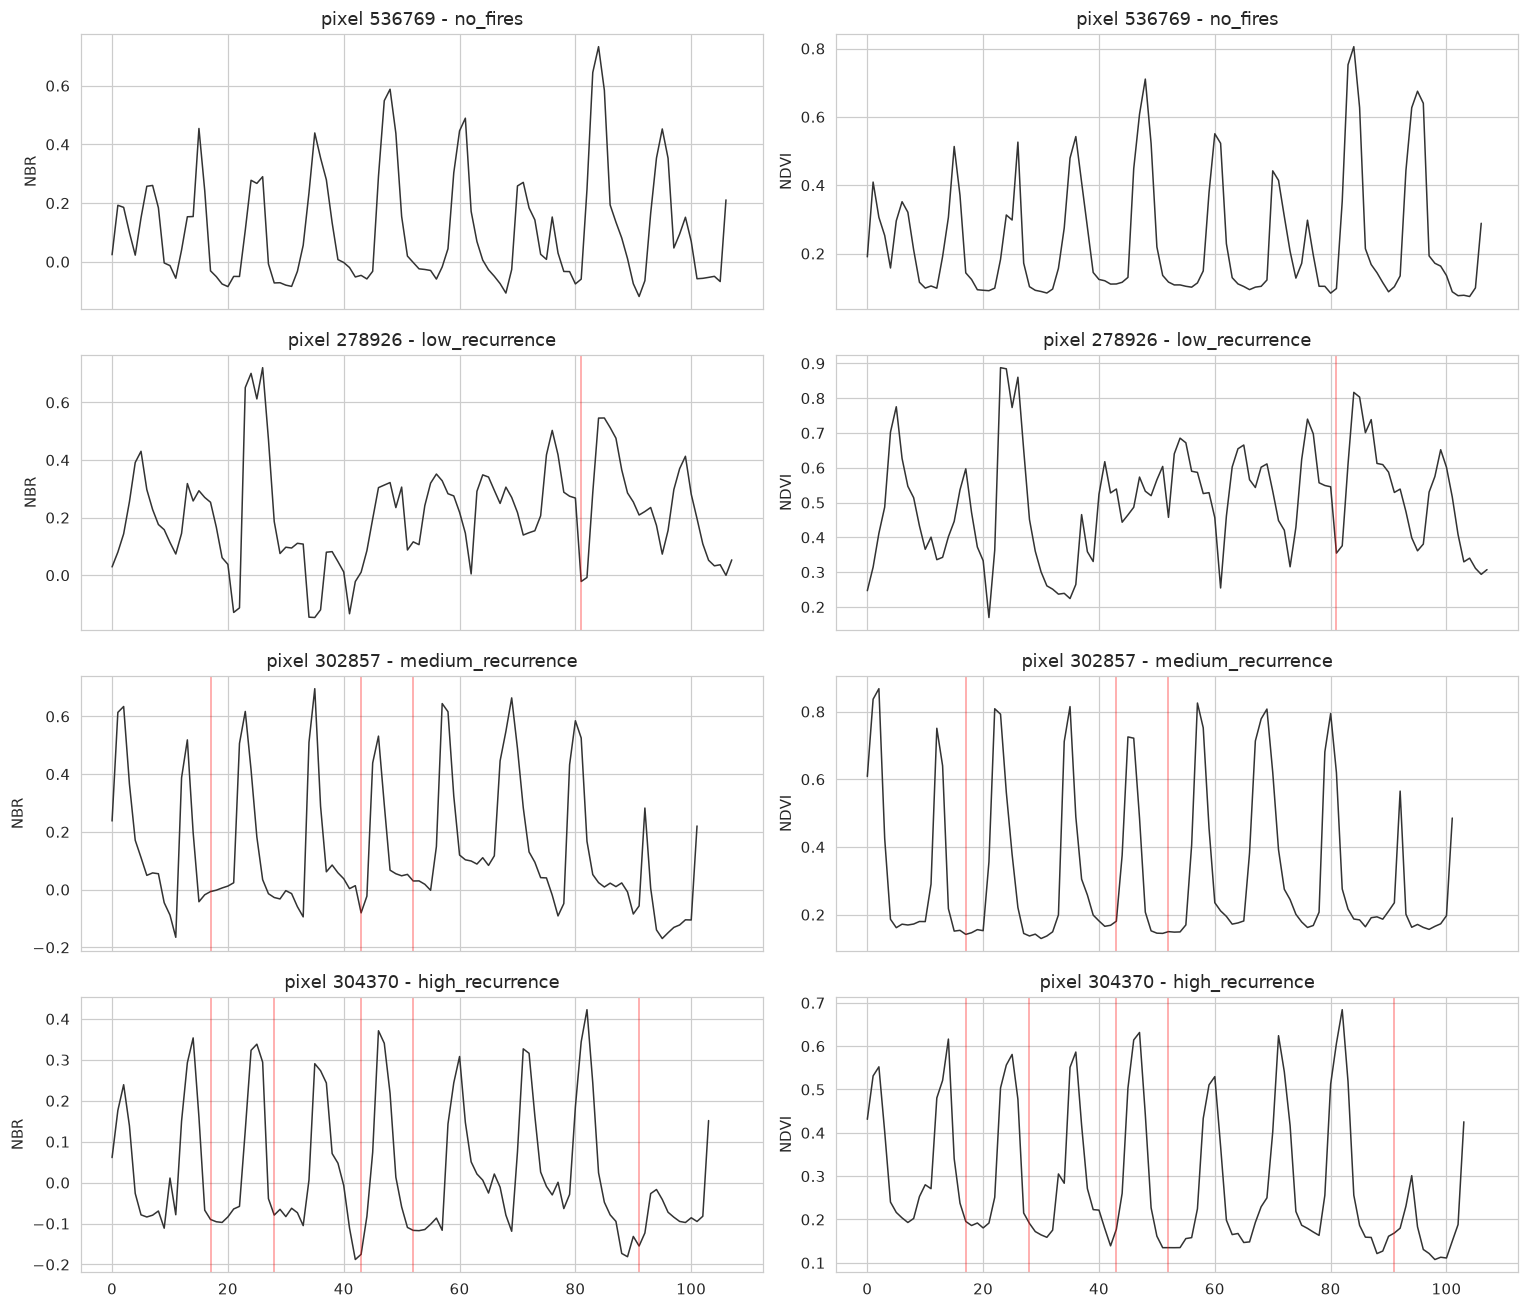

In [13]:
def plot_pixel_timeseries(pid, ax_pair):
    g = df[df["pixel_id"] == pid].sort_values(["year", "month"])
    fire_months = g[g["burned"] == 1]

    for ax, col in zip(ax_pair, ["NBR", "NDVI"]):
        ax.plot(range(len(g)), g[col].values, color="#333", linewidth=1)
        for _, row in fire_months.iterrows():
            t = ((int(row["year"]) - config.START_YEAR) * 12 +
                 (int(row["month"]) - 1))
            ax.axvline(t, color="red", alpha=0.4, linewidth=1)
        ax.set_ylabel(col)
        ax.set_title(f"pixel {pid} - {g['pixel_type'].iloc[0]}")


examples = (df.groupby("pixel_id")
              .agg(pt=("pixel_type", "first"),
                   n_fires=("burned", "sum"))
              .reset_index())

picks = {}
for pt in config.PIXEL_TYPES:
    sub = examples[examples["pt"] == pt]
    if len(sub):
        picks[pt] = sub.sample(1, random_state=config.SEED)["pixel_id"].iloc[0]

fig, axes = plt.subplots(len(picks), 2, figsize=(14, 3 * len(picks)),
                         sharex=True)
for i, (pt, pid) in enumerate(picks.items()):
    plot_pixel_timeseries(pid, axes[i])
plt.tight_layout()
plt.show()

### 5.2 Mean NBR around fire events

For all burned pixels, align time series to the fire month (t=0) and
plot the average NBR trajectory before and after. Confirms the fire
signal is empirically present and quantifies the typical drop and
recovery duration.

Fire events with a full +/-12-month window: 511


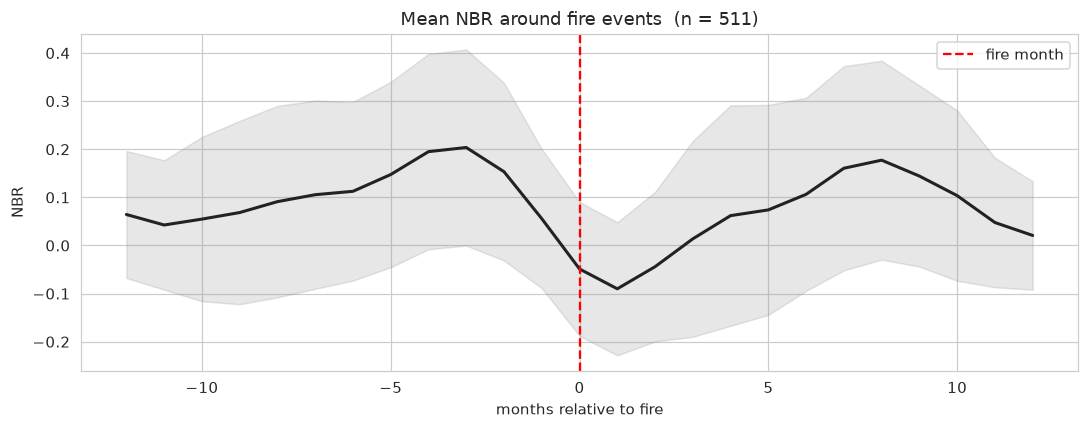

In [14]:
WINDOW = 12
nbr_curves = []

burned_pids = df.loc[df["burned"] == 1, "pixel_id"].unique()[:500]

# Subset once, then group: the previous form re-scanned all ~64M rows for
# each of the 500 pixels.
sub = df[df["pixel_id"].isin(burned_pids)]

for pid, g in sub.groupby("pixel_id", sort=False):
    g = g.sort_values(["year", "month"])
    nbr = g["NBR"].values
    fires = np.where(g["burned"].values == 1)[0]
    for t in fires:
        lo, hi = t - WINDOW, t + WINDOW + 1
        if lo < 0 or hi > len(nbr):
            continue
        nbr_curves.append(nbr[lo:hi])

nbr_curves = np.array(nbr_curves)
print(f"Fire events with a full +/-{WINDOW}-month window: {len(nbr_curves)}")

if len(nbr_curves) == 0:
    print("No complete windows - nothing to plot.")
else:
    mean = np.nanmean(nbr_curves, axis=0)
    std  = np.nanstd(nbr_curves, axis=0)
    x    = np.arange(-WINDOW, WINDOW + 1)

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(x, mean, color="#222", linewidth=2)
    ax.fill_between(x, mean - std, mean + std, alpha=0.2, color="#888")
    ax.axvline(0, color="red", linestyle="--", label="fire month")
    ax.set_xlabel("months relative to fire")
    ax.set_ylabel("NBR")
    ax.set_title(f"Mean NBR around fire events  (n = {len(nbr_curves)})")
    ax.legend()
    plt.tight_layout()
    plt.show()

## 6. Feature selection decision

The final feature list is `config.MODEL_FEATURES`: 26 spectral features
(five raw bands, seven indices, seven z-scores, seven raw anomalies)
plus 20 land-cover one-hot features (10 categories × 2 years). The
VIF table above is documentation for the thesis — features with high
VIF that still carry distinct ecological information (for example NBR
vs. NBR_zscore, which convey different reference frames) are retained
by design. NBR_dnbr is excluded before this step because it is
analytically identical to NBR_anomaly.

In [15]:
selected_features = list(config.MODEL_FEATURES)

with open(config.FILES["selected_features"], "w") as f:
    json.dump({
        "selected": selected_features,
        "rationale": (
            "All MODEL_FEATURES retained. NBR_dnbr excluded upstream due to "
            "perfect collinearity with NBR_anomaly under the "
            "seasonal-baseline formulation. Remaining spectral redundancy "
            "handled by attention weights and weight decay. Land-cover "
            "one-hot features carry no scalar redundancy by construction."),
    }, f, indent=2)

print(f"Wrote {len(selected_features)} features to "
      f"{config.FILES['selected_features']}")
print(f"  Spectral: {len(selected_features) - len(config.LC_FEATURES)}")
print(f"  LC:       {len(config.LC_FEATURES)}")

Wrote 52 features to /home/od/thesisv4/data/eda/selected_features.json
  Spectral: 32
  LC:       20
